In [1]:
import numpy as np
import pandas as pd

# example: load one CSV you already saved
df = pd.read_csv("/global/homes/z/zhaozhon/project/results/tables/pred_counts_order1_all_m20_bin1_z2.3-2.4.csv")

obs = df["N_obs"].to_numpy(dtype=float)
lam = df["N_exp_mean"].to_numpy(dtype=float)

z = (obs - lam) / np.sqrt(lam)

out = pd.DataFrame({
    "m_center": df["m_center"],
    "N_obs": obs,
    "lambda_mean": lam,
    "z_sigma": z,
    "abs_z": np.abs(z),
})

out = out.sort_values("abs_z", ascending=False)
out.head(10)

,m_center,N_obs,lambda_mean,z_sigma,abs_z
5,18.522116,202.0,182.499880,1.443464,1.443464
4,18.213310,113.0,100.684481,1.227359,1.227359
12,20.683764,2532.0,2476.995729,1.105182,1.105182
8,19.448537,822.0,793.254524,1.020618,1.020618
11,20.374957,1964.0,2007.728484,-0.975915,0.975915
7,19.139730,495.0,517.061313,-0.970198,0.970198
3,17.904503,63.0,55.881173,0.952304,0.952304
6,18.830923,300.0,316.265225,-0.914607,0.914607
10,20.066150,1594.0,1558.684600,0.894510,0.894510
18,22.536605,3634.0,3580.935576,0.886758,0.886758


In [2]:
imax = np.argmax(np.abs(z))
print("Worst bin:")
print("m_center =", df['m_center'].iloc[imax])
print("N_obs    =", obs[imax])
print("lambda   =", lam[imax])
print("z_sigma  =", z[imax])

Worst bin:
m_center = 18.52211637496948
N_obs    = 202.0
lambda   = 182.49987985737087
z_sigma  = 1.4434641283694165


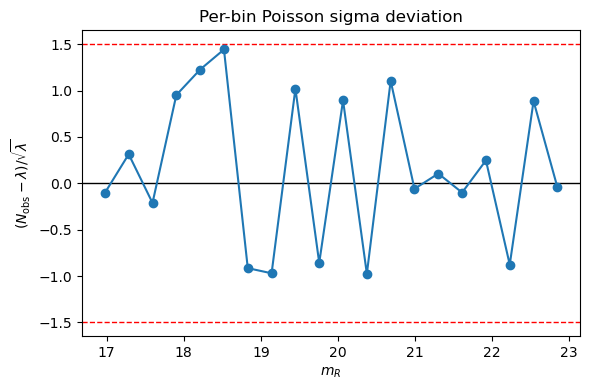

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.axhline(0, color="k", lw=1)
plt.axhline(1.5, color="r", ls="--", lw=1)
plt.axhline(-1.5, color="r", ls="--", lw=1)
plt.plot(df["m_center"], z, marker="o")
plt.xlabel(r"$m_R$")
plt.ylabel(r"$(N_{\rm obs}-\lambda)/\sqrt{\lambda}$")
plt.title("Per-bin Poisson sigma deviation")
plt.tight_layout()
plt.show()